In [1]:
## 1. Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_auc_score

from pathlib import Path

data_file = "cleaneddataset.csv" if Path("cleaneddataset.csv").exists() else "Books_Data_Clean.csv"
df = pd.read_csv(data_file)
df.columns = df.columns.str.strip()
df = df.drop(columns=["index"], errors="ignore")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1070, 14)


,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,1975.0,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,34160.0,20496.0,4.88,1,HarperCollins Publishers,7000
1,1987.0,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,12437.5,7462.5,1.99,2,HarperCollins Publishers,6250
2,2015.0,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,47795.0,28677.0,8.69,3,"Amazon Digital Services, Inc.",5500
3,2008.0,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.04,150898,fiction,41250.0,24750.0,7.50,3,Hachette Book Group,5500
4,2011.0,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.04,198283,genre fiction,37952.5,22771.5,7.99,4,Penguin Group (USA) LLC,4750


In [2]:
## 2. Create the target
df["units sold"] = pd.to_numeric(df["units sold"], errors="coerce")
threshold = df["units sold"].quantile(0.75)
df["High_Selling"] = (df["units sold"] >= threshold).astype(int)

print("High-selling threshold:", threshold)
print(df["High_Selling"].value_counts())

High-selling threshold: 5312.25
High_Selling
0    802
1    268
Name: count, dtype: int64


## 3. Probability distributions

We examine the observed distribution of units sold and book average ratings. The histograms show the empirical distributions, while summary statistics describe their centre and spread. Because sales data can be skewed, we do not assume that units sold follows a normal distribution. We also estimate the observed probability that a randomly selected book belongs to the `High_Selling` class.


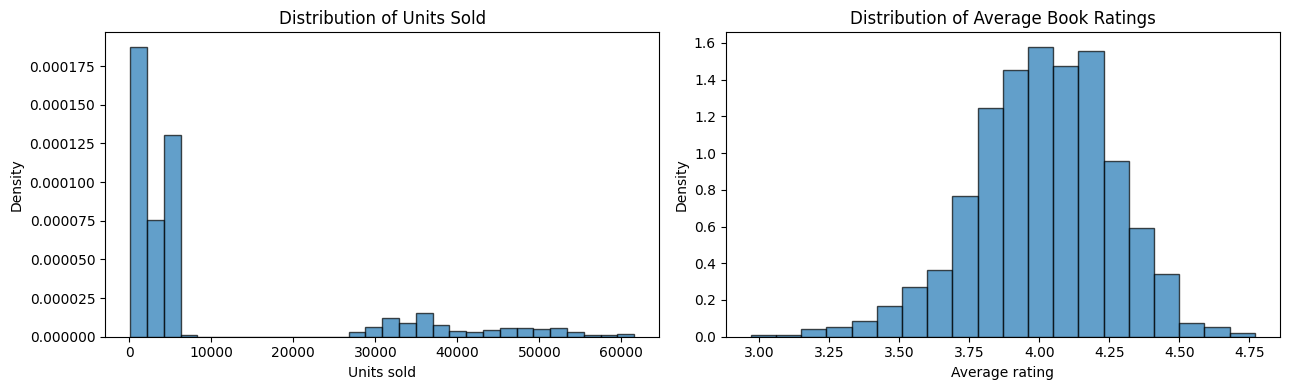

UNITS SOLD
Count: 1070
Mean: 9676.98
Median: 3924.0
Standard deviation: 15370.57
Skewness: 1.757

BOOK AVERAGE RATING
Count: 1070
Mean: 4.007
Median: 4.015
Standard deviation: 0.247
Skewness: -0.389

EMPIRICAL CLASS PROBABILITIES
P(High-Selling): 0.2505
P(Not High-Selling): 0.7495


In [3]:
units = pd.to_numeric(df["units sold"], errors="coerce").dropna()
ratings = pd.to_numeric(df["Book_average_rating"], errors="coerce").dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(units, bins=30, density=True, alpha=0.7, edgecolor="black")
axes[0].set_title("Distribution of Units Sold")
axes[0].set_xlabel("Units sold")
axes[0].set_ylabel("Density")

axes[1].hist(ratings, bins=20, density=True, alpha=0.7, edgecolor="black")
axes[1].set_title("Distribution of Average Book Ratings")
axes[1].set_xlabel("Average rating")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

print("UNITS SOLD")
print("Count:", units.count())
print("Mean:", round(units.mean(), 2))
print("Median:", round(units.median(), 2))
print("Standard deviation:", round(units.std(), 2))
print("Skewness:", round(units.skew(), 3))

print()
print("BOOK AVERAGE RATING")
print("Count:", ratings.count())
print("Mean:", round(ratings.mean(), 3))
print("Median:", round(ratings.median(), 3))
print("Standard deviation:", round(ratings.std(), 3))
print("Skewness:", round(ratings.skew(), 3))

p_high = df["High_Selling"].mean()
p_not_high = 1 - p_high
print()
print("EMPIRICAL CLASS PROBABILITIES")
print("P(High-Selling):", round(p_high, 4))
print("P(Not High-Selling):", round(p_not_high, 4))


## 4. Central Limit Theorem (CLT)

The Central Limit Theorem states that, under suitable conditions, the sampling distribution of the sample mean approaches a normal distribution as sample size increases, even if the original population is not normally distributed. Here, we repeatedly sample book ratings with replacement and calculate their means. The histogram of sample means illustrates the sampling distribution. This is a demonstration of the CLT, not a claim that the original ratings are normally distributed.


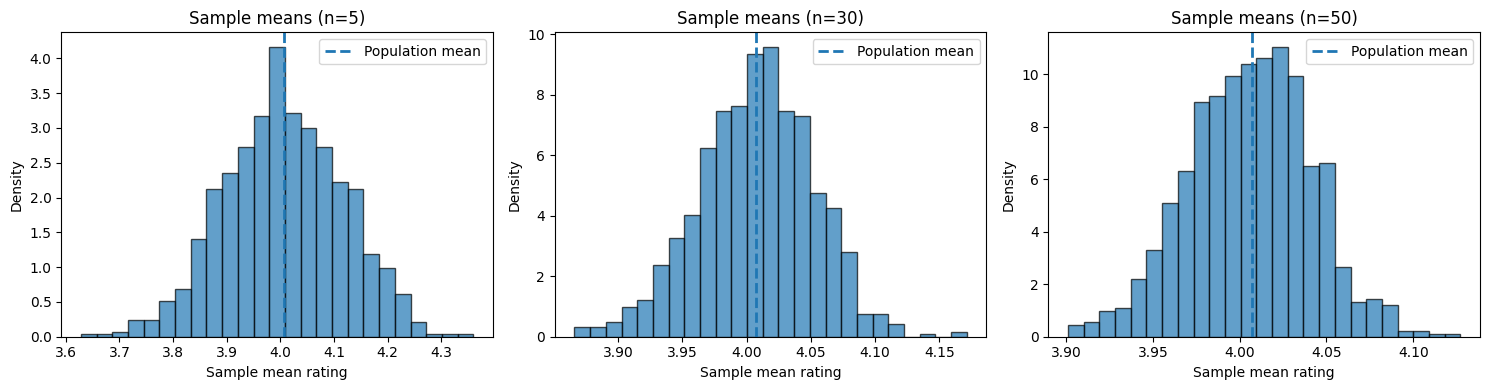

Population mean rating: 4.007
Population standard deviation: 0.2472
Sample size 5: theoretical standard error = 0.1106
Sample size 30: theoretical standard error = 0.0451
Sample size 50: theoretical standard error = 0.0350


In [4]:
rating_population = pd.to_numeric(df["Book_average_rating"], errors="coerce").dropna().to_numpy()

rng = np.random.default_rng(42)
sample_sizes = [5, 30, 50]
repetitions = 1000

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, n in zip(axes, sample_sizes):
    sample_means = np.array([
        rng.choice(rating_population, size=n, replace=True).mean()
        for _ in range(repetitions)
    ])
    ax.hist(sample_means, bins=25, density=True, edgecolor="black", alpha=0.7)
    ax.axvline(rating_population.mean(), linestyle="--", linewidth=2,
               label="Population mean")
    ax.set_title(f"Sample means (n={n})")
    ax.set_xlabel("Sample mean rating")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

print("Population mean rating:", round(rating_population.mean(), 4))
print("Population standard deviation:", round(rating_population.std(ddof=1), 4))
for n in sample_sizes:
    theoretical_se = rating_population.std(ddof=1) / np.sqrt(n)
    print(f"Sample size {n}: theoretical standard error = {theoretical_se:.4f}")


## 5. Prepare features for classification

The classifier predicts whether a book belongs to the dataset's top quartile by units sold. This is a proxy for high sales, not an official bestseller label. The input features are publishing year, author, language, author rating, average book rating, book ratings count, genre, sale price, and publisher. The target-defining `units sold` and potential leakage columns (`sales rank`, `gross sales`, and `publisher revenue`) are excluded from the model inputs.


In [5]:
## 6. Select features and handle missing values
excluded = [
    "High_Selling", "units sold", "sales rank",
    "gross sales", "publisher revenue", "Book Name"
]
X = df.drop(columns=excluded, errors="ignore")
y = df["High_Selling"]

X = X.copy()

numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())

for col in categorical_cols:
    mode_values = X[col].mode()
    fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
    X[col] = X[col].fillna(fill_value)

print("Missing values remaining:", X.isnull().sum().sum())
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Missing values remaining: 0
Numeric columns: ['Publishing Year', 'Book_average_rating', 'Book_ratings_count', 'sale price']
Categorical columns: ['Author', 'language_code', 'Author_Rating', 'genre', 'Publisher']


In [6]:
## 7. Encode categorical columns and split data
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 856
Testing rows: 214


In [7]:
## 8. Scale numeric features
scaler = StandardScaler()
X_train[numeric_cols] = X_train[numeric_cols].astype(float)
X_test[numeric_cols] = X_test[numeric_cols].astype(float)
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [8]:
## 9. Train and compare models
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced", max_depth=8),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
}

trained_models = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Decision Tree,0.621,0.369,0.704,0.484,0.657
0,Logistic Regression,0.645,0.333,0.407,0.367,0.637
2,Random Forest,0.738,0.417,0.093,0.152,0.734


Best model: Decision Tree
                  precision    recall  f1-score   support

Not High-Selling       0.86      0.59      0.70       160
    High-Selling       0.37      0.70      0.48        54

        accuracy                           0.62       214
       macro avg       0.61      0.65      0.59       214
    weighted avg       0.73      0.62      0.65       214



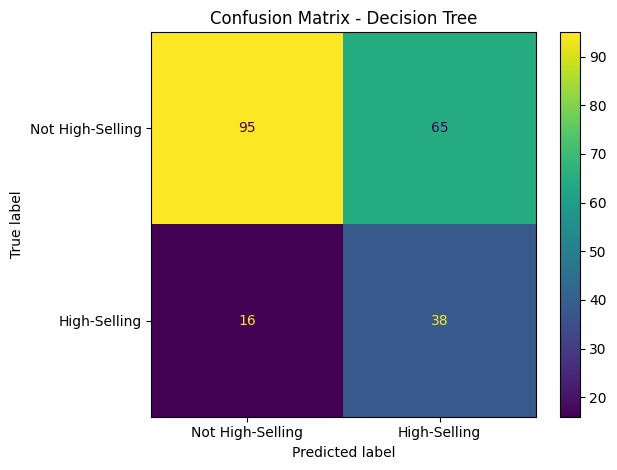

In [9]:
## 10. Evaluate the best model
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(
    y_test, best_predictions,
    labels=[0, 1],
    target_names=["Not High-Selling", "High-Selling"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Not High-Selling", "High-Selling"],
    values_format="d"
)
plt.title("Confusion Matrix - " + best_name)
plt.tight_layout()
plt.show()

In [10]:
## 11. Example prediction
sample = X_test.iloc[[0]]
actual = y_test.iloc[0]
predicted = best_model.predict(sample)[0]
probability = best_model.predict_proba(sample)[0, 1]

print("Actual:", "High-Selling" if actual == 1 else "Not High-Selling")
print("Predicted:", "High-Selling" if predicted == 1 else "Not High-Selling")
print("Probability of High-Selling:", round(probability * 100, 2), "%")

Actual: Not High-Selling
Predicted: High-Selling
Probability of High-Selling: 73.13 %


## 12. Hypothesis testing

These statistical tests complement the classification models. The target `High_Selling` is a proxy defined as the top 25% of books by `units sold`; it is not an official bestseller label. Use a significance level of 0.05. A small p-value provides evidence against the null hypothesis, but does not establish causation.

In [11]:
from scipy.stats import chi2_contingency

test_data = df[["genre", "High_Selling"]].dropna()
contingency_table = pd.crosstab(test_data["genre"], test_data["High_Selling"])

chi2_stat, chi2_p_value, chi2_dof, expected = chi2_contingency(contingency_table)

print("CHI-SQUARE TEST: Genre vs High-Selling Category")
print("H0: Genre and High_Selling are independent.")
print("H1: Genre and High_Selling are associated.")
print("\nContingency table:")
display(contingency_table)
print("Chi-square statistic:", round(chi2_stat, 4))
print("Degrees of freedom:", chi2_dof)
print("P-value:", chi2_p_value)

if chi2_p_value < 0.05:
    print("Decision: Reject H0. There is evidence of an association between genre and selling category.")
else:
    print("Decision: Fail to reject H0. There is insufficient evidence of an association between genre and selling category.")

CHI-SQUARE TEST: Genre vs High-Selling Category
H0: Genre and High_Selling are independent.
H1: Genre and High_Selling are associated.

Contingency table:


High_Selling,0,1
genre,,
children,8,7
fiction,50,12
genre fiction,619,203
nonfiction,125,46


Chi-square statistic: 5.1716
Degrees of freedom: 3
P-value: 0.1596530291515413
Decision: Fail to reject H0. There is insufficient evidence of an association between genre and selling category.


In [12]:
from scipy.stats import ttest_ind

rating_data = df[["Book_average_rating", "High_Selling"]].copy()
rating_data["Book_average_rating"] = pd.to_numeric(rating_data["Book_average_rating"], errors="coerce")
high_ratings = rating_data.loc[rating_data["High_Selling"] == 1, "Book_average_rating"].dropna()
other_ratings = rating_data.loc[rating_data["High_Selling"] == 0, "Book_average_rating"].dropna()

t_stat, t_p_value = ttest_ind(high_ratings, other_ratings, equal_var=False)

print("WELCH'S TWO-SAMPLE T-TEST: Average Rating")
print("H0: Mean book rating is equal for high-selling and not-high-selling books.")
print("H1: Mean book rating differs between the two groups.")
print("\nHigh-selling mean rating:", round(high_ratings.mean(), 4))
print("Not-high-selling mean rating:", round(other_ratings.mean(), 4))
print("T statistic:", round(t_stat, 4))
print("P-value:", t_p_value)

if t_p_value < 0.05:
    print("Decision: Reject H0. There is evidence that mean book ratings differ between the groups.")
else:
    print("Decision: Fail to reject H0. There is insufficient evidence that mean book ratings differ between the groups.")

WELCH'S TWO-SAMPLE T-TEST: Average Rating
H0: Mean book rating is equal for high-selling and not-high-selling books.
H1: Mean book rating differs between the two groups.

High-selling mean rating: 3.9912
Not-high-selling mean rating: 4.0123
T statistic: -1.245
P-value: 0.21372352379270068
Decision: Fail to reject H0. There is insufficient evidence that mean book ratings differ between the groups.


## 13. On what basis does the model predict?

1. **Target definition:** calculate the 75th percentile of `units sold`; books at or above this threshold are labelled `High_Selling = 1`, and the rest are labelled `0`.
2. **Learning from examples:** the model learns statistical patterns between the available book attributes and this label using the training set.
3. **Preprocessing:** missing numeric values are filled with the training-independent dataset median in this notebook, categorical values are one-hot encoded, and numeric features are standardised. (For a stricter production evaluation, imputation should be fitted on training data only.)
4. **Model-specific basis:** Logistic Regression learns feature weights; Decision Tree learns feature-based rules; Random Forest combines predictions from many decision trees.
5. **Final output:** the model predicts the class with its learned decision rule. `predict_proba` gives the model's estimated probability for the high-selling class; it is not a guarantee that the book will sell well.
6. **Model selection:** models are compared using held-out test data. The notebook selects the model with the highest F1 score, which balances precision and recall.

**Important limitation:** the result depends on this dataset, its features, and the proxy target. The model estimates membership in the top-sales group represented in this dataset; it does not establish that a book will become an official bestseller or prove cause-and-effect relationships.
